# Two-cell pushing with built-in contact models: comparison across tools

Unit test with built-in contact models (Figure 3F). Each tool uses its own contact law, so there is no common reference; the figure shows the centre-to-centre distance normalised by one cell diameter (10 um), with the contact distance (1.0) as a guide.

Protocols differ by design (Methods): BioDynaMo imposes eleven 1 um displacements per cell, CompuTiX removes the driving force once the overlap exceeds 1 um, TiSim stops the approach at 9 um, Chaste releases the cells at one diameter, and PhysiCell starts directly from 10% overlap (9 um).

Inputs (repository-relative):
- BioDynaMo: `Biodynamo/mechanics_pushing/results_timestep0.1/positions.csv` (one row per 0.1 min step)
- Chaste: `Chaste/mechanics_pushing/results/results.viznodelocations` (used only if present; assumed 10 um per length unit and time in hours, question 8.12)
- CompuTiX: `CompuTiX/mechanics_pushing/results/mechanics_pushing.yaml` (time in s, positions in m)
- PhysiCell: `PhysiCell/results/mechanics_pushing/physicell_mechanics_pushing.csv`, generated below from the local `.mat` files if it does not exist
- TiSim: `Tisim/mechanics_pushing/mechanics_pushing.csv` (time in min, distance in um)


In [1]:
import sys
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

# Repository root: the first folder above the working directory that holds
# ResultAnalysis/figure_style.py, so the notebook runs from any clone.
_start = Path.cwd().resolve()
ROOT = next((p for p in (_start, *_start.parents) if (p / 'ResultAnalysis' / 'figure_style.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError(f'Run this notebook from inside the observatory_benchmark repository (cwd: {_start})')
sys.path.insert(0, str(ROOT / 'ResultAnalysis'))
import figure_style as ns

CELL_DIAMETER_UM = 10.0
PLOT_DIR = ROOT / 'ResultAnalysis' / 'plots' / 'mechanics_pushing_builtin'


## PhysiCell: derived table from the local `.mat` files (skipped if the CSV already exists)

In [2]:
PC_DIR = ROOT / 'PhysiCell' / 'results' / 'mechanics_pushing'
PC_CSV = PC_DIR / 'physicell_mechanics_pushing.csv'

if not PC_CSV.is_file():
    from scipy.io import loadmat
    records = []
    for xml_path in sorted(PC_DIR.glob('output*.xml')):
        root = ET.parse(xml_path).getroot()
        current_time = float(root.findtext('.//current_time'))
        mat_name = root.findtext('.//simplified_data/filename')
        mat_path = PC_DIR / mat_name
        if not mat_path.is_file():
            print(f'{mat_name} not found: PhysiCell left out (the .mat files are needed to build {PC_CSV.name})')
            records = []
            break
        cells = loadmat(mat_path)['cells']
        positions = cells[1:4, :].T
        radii = cells[37, :]
        if positions.shape[0] != 2:
            raise ValueError(f'Expected 2 cells, found {positions.shape[0]} in {mat_name}')
        distance = float(np.linalg.norm(positions[0] - positions[1]))
        records.append({'time_min': current_time,
                        'distance_um': distance,
                        'radius_sum_um': float(radii[0] + radii[1]),
                        'overlap_um': float(radii[0] + radii[1] - distance)})
    if records:
        pc = pd.DataFrame.from_records(records).sort_values('time_min').reset_index(drop=True)
        pc['distance_over_diameter'] = pc['distance_um'] / pc['radius_sum_um']
        pc.to_csv(PC_CSV, index=False)
        print(f'Wrote {PC_CSV.relative_to(ROOT)} ({len(pc)} rows)')
else:
    print(f'Using existing {PC_CSV.relative_to(ROOT)}')


Using existing PhysiCell/results/mechanics_pushing/physicell_mechanics_pushing.csv


## Load every tool as time (min) and centre-to-centre distance (um)

In [3]:
def load_biodynamo():
    p = ROOT / 'Biodynamo' / 'mechanics_pushing' / 'results_timestep0.1' / 'positions.csv'
    df = pd.read_csv(p, sep=r'\t|,', header=None, engine='python')
    step = df[0].to_numpy(float)
    d = (df[4] - df[1]).to_numpy(float)   # x of cell 1 minus x of cell 0, um
    return step * 0.1, d, p                # simulation_time_step = 0.1 min

def load_chaste():
    p = ROOT / 'Chaste' / 'mechanics_pushing' / 'results' / 'results.viznodelocations'
    if not p.is_file():
        return None
    ch = pd.read_csv(p, sep=r'\t| ', header=None, engine='python')
    d = (ch[4] - ch[1]).abs().to_numpy(float) * CELL_DIAMETER_UM  # 10 um per length unit (question 8.12)
    t = ch[0].to_numpy(float) * 60.0       # hours -> min (assumed; to be confirmed by the Chaste team, question 8.12)
    return t, d, p

def load_computix():
    p = ROOT / 'CompuTiX' / 'mechanics_pushing' / 'results' / 'mechanics_pushing.yaml'
    c = yaml.safe_load(open(p))
    t = np.array(c['t']['values'], float) / 60.0                       # s -> min
    x = np.array(c['Cells']['values']['x']['values'], float)
    d = np.abs(x[:, 1] - x[:, 0]) * 1e6                                 # m -> um
    return t, d, p

def load_physicell():
    p = PC_CSV
    if not p.is_file():
        return None
    pc = pd.read_csv(p)
    return pc['time_min'].to_numpy(float), pc['distance_um'].to_numpy(float), p

def load_tisim():
    p = ROOT / 'Tisim' / 'mechanics_pushing' / 'mechanics_pushing.csv'
    tp = pd.read_csv(p)
    return tp['time (min)'].to_numpy(float), tp['distance (um)'].to_numpy(float), p

LOADERS = {'BioDynaMo': load_biodynamo, 'Chaste': load_chaste, 'CompuTiX': load_computix,
           'PhysiCell': load_physicell, 'TiSim': load_tisim}

data = {}
for tool, loader in LOADERS.items():
    out = loader()
    if out is None:
        print(f'{tool}: no data in the repository, left out of the figure')
        continue
    t, d, p = out
    data[tool] = (t, d)
    print(f'{tool}: {len(t)} samples, t = {t[0]:g} to {t[-1]:g} min, from {Path(p).relative_to(ROOT)}')


BioDynaMo: 100 samples, t = 0 to 9.9 min, from Biodynamo/mechanics_pushing/results_timestep0.1/positions.csv
Chaste: 501 samples, t = 0 to 5 min, from Chaste/mechanics_pushing/results/results.viznodelocations
CompuTiX: 100 samples, t = 0 to 9.9 min, from CompuTiX/mechanics_pushing/results/mechanics_pushing.yaml
PhysiCell: 101 samples, t = 0 to 10 min, from PhysiCell/results/mechanics_pushing/physicell_mechanics_pushing.csv
TiSim: 6000 samples, t = 0 to 9.99833 min, from Tisim/mechanics_pushing/mechanics_pushing.csv


## Summary: final distance, minimum distance, residual overlap

In [4]:
rows = []
for tool, (t, d) in data.items():
    i = int(np.argmin(d))
    rows.append({'tool': tool,
                 'start_distance_um': d[0],
                 'min_distance_um': d[i], 't_min_min': t[i],
                 'final_distance_um': d[-1], 't_final_min': t[-1],
                 'final_distance_over_diameter': d[-1] / CELL_DIAMETER_UM,
                 'residual_overlap_um': CELL_DIAMETER_UM - d[-1]})
summary = pd.DataFrame(rows).set_index('tool')
pd.set_option('display.float_format', lambda v: f'{v:.6g}')
summary


,start_distance_um,min_distance_um,t_min_min,final_distance_um,t_final_min,final_distance_over_diameter,residual_overlap_um
tool,,,,,,,
BioDynaMo,28,8.39496,1,9.375,9.9,0.9375,0.625
Chaste,30,8.8308,1.06,9.979,5,0.9979,0.021
CompuTiX,30,7.922,1.2,9.0954,9.9,0.90954,0.9046
PhysiCell,30,8.99827,1,9.73733,10,0.973733,0.262673
TiSim,30,8.97035,1.05167,9.87875,9.99833,0.987875,0.12125


## Figure 3F: distance normalised by the cell diameter

Saved png: /home/tntiniak/Work/observatory_benchmark/ResultAnalysis/figures/mechanics_pushing_builtin/png/distance_over_time.png
Saved svg: /home/tntiniak/Work/observatory_benchmark/ResultAnalysis/figures/mechanics_pushing_builtin/svg/distance_over_time.svg
Saved source_data: /home/tntiniak/Work/observatory_benchmark/ResultAnalysis/figures/mechanics_pushing_builtin/source_data/distance_over_time.csv


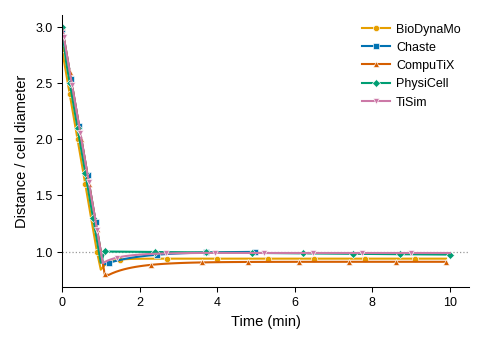

In [5]:
with ns.style():
    fig, ax = plt.subplots(figsize=ns.size(ns.SINGLE_COL_MM, 60))
    for tool in ns.TOOL_ORDER:
        if tool not in data:
            continue
        t, d = data[tool]
        ax.plot(t, d / CELL_DIAMETER_UM, **ns.tool_series(tool, kind='line'))
    ax.axhline(1.0, color='0.6', linewidth=0.6, linestyle=':', zorder=1)
    ax.set_xlabel('Time (min)')
    ax.set_ylabel('Distance / cell diameter')
    ax.set_xlim(left=0)
    ns.style_axes(ax)
    handles, labels = ax.get_legend_handles_labels()
    ns.ordered_legend(ax, handles, labels, frameon=False, loc='upper right')
    ns.export(fig, 'mechanics_pushing_builtin', 'distance_over_time', root=ROOT,
              also=PLOT_DIR, also_stem='mechanics_pushing_builtin_distance')
    plt.show()
